# Will this order be late? Training

When a customer places an order on Olist, I want to predict whether it will arrive after the date we promised them. If risky orders can be flagged at purchase time, the company can warn the customer, push back the promised date or change the delivery plan.

`uv run python main.py train` runs this notebook from top to bottom and saves everything into `artifacts/`. The app only reads those files, it never trains anything.

1. Data and features
2. Time split
3. Preprocessing
4. Baselines and metrics
5. One model, three ways
6. Tuning
7. Threshold
8. Test
9. Save

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             log_loss, precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 1. Data and features

The data is the 20,000 order sample in `data/sampled/`, made by `sample_data.py` (delivered orders only, 2016 removed). An order is late if it was delivered after the estimated delivery date.

I tried 13 groups of features in `feature_selection.ipynb` and kept the 5 that helped on validation. All of them are known when the order is placed.

| feature | what it is |
|---|---|
| `promised_days` | days between purchase and the promised delivery date |
| `customer_state` | state the order is delivered to |
| `log_distance_km` | seller to customer distance, averaged over the items, then log |
| `log_freight` | total freight paid for the order, then log |
| `n_sellers` | number of different sellers in the order, capped at 3 |

Distance is the haversine (straight line on a sphere) distance between the zip code centroids of the seller and the customer. Freight and distance have a few very large values, so I take `log1p` to stop them from dominating. Almost every order has one seller, so I cap `n_sellers` at 3. These are fixed formulas and nothing is learned from the data, so it is fine to do them before the split.

In [2]:
SAMPLED = Path("data/sampled")

orders = pd.read_csv(SAMPLED / "orders.csv",
                     parse_dates=["order_purchase_timestamp", "order_estimated_delivery_date"])
items = pd.read_csv(SAMPLED / "order_items.csv")
customers = pd.read_csv(SAMPLED / "customers.csv")
sellers = pd.read_csv(SAMPLED / "sellers.csv")
geo = pd.read_csv(SAMPLED / "geolocation.csv").set_index("geolocation_zip_code_prefix")   # one lat/lng per zip prefix

print("orders:", orders.shape, "| items:", items.shape)

orders: (20001, 9) | items: (22927, 7)


In [3]:
def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))


o = orders.set_index("order_id")
df = pd.DataFrame({"purchase_ts": o["order_purchase_timestamp"], "late": o["late"].astype(int)})
df["promised_days"] = (o["order_estimated_delivery_date"] - o["order_purchase_timestamp"]) / pd.Timedelta(days=1)
df["customer_state"] = o["customer_id"].map(customers.set_index("customer_id")["customer_state"])

# one row per item, with the seller and customer zip codes, for the distance and the per-order sums
it = (items.merge(orders[["order_id", "customer_id"]], on="order_id")
           .merge(customers[["customer_id", "customer_zip_code_prefix"]], on="customer_id")
           .merge(sellers[["seller_id", "seller_zip_code_prefix"]], on="seller_id"))
seller_xy = geo.reindex(it["seller_zip_code_prefix"])
customer_xy = geo.reindex(it["customer_zip_code_prefix"])
it["distance_km"] = haversine_km(seller_xy["geolocation_lat"].values, seller_xy["geolocation_lng"].values,
                                 customer_xy["geolocation_lat"].values, customer_xy["geolocation_lng"].values)

per_order = it.groupby("order_id")
df["n_sellers"] = per_order["seller_id"].nunique().clip(upper=3)
df["log_distance_km"] = np.log1p(per_order["distance_km"].mean())
df["log_freight"] = np.log1p(per_order["freight_value"].sum())

df = df.reset_index()[["order_id", "purchase_ts", "late",
                       "n_sellers", "promised_days", "customer_state", "log_distance_km", "log_freight"]]
print(df.shape, "| late rate:", round(df["late"].mean(), 4))
df.head()

(20001, 8) | late rate: 0.0679


,order_id,purchase_ts,late,n_sellers,promised_days,customer_state,log_distance_km,log_freight
0,597bd074d7874048131c67581f0556d4,2017-01-31 11:54:14,0,1,36.504005,SP,5.917491,2.746630
1,944f618b790d6d01c2c78750fc0f700a,2017-01-17 15:01:33,0,1,40.373924,MG,5.913941,3.402530
2,dba1b6fd34a7fd5961e829fa902ca702,2017-01-28 23:29:12,0,1,45.021389,SP,4.900311,2.944439
3,24e1c731364b64c76d98e985bfdbef77,2017-01-17 20:38:15,0,1,40.140104,PR,5.883346,2.988204
4,ae162713f33901220faa2a22c2bdba45,2017-01-31 14:38:41,0,1,36.389803,SP,4.442867,3.565298


## 2. Time split

The model has to predict orders that have not happened yet, so I split by date and not at random. A random split would put orders from the same weeks in train and test and make the model look better than it is.

- test: the last 3 months
- validation: the 2 months before that
- train: everything earlier

Validation is for tuning and for choosing the threshold. I look at test once, at the end. The cutoffs are counted back from the last month in the data.

In [4]:
last_month = df["purchase_ts"].max().to_period("M")
test_start = (last_month - 2).start_time
val_start = (last_month - 4).start_time

train = df[df["purchase_ts"] < val_start]
val = df[(df["purchase_ts"] >= val_start) & (df["purchase_ts"] < test_start)]
test = df[df["purchase_ts"] >= test_start]

assert len(train) + len(val) + len(test) == len(df)
assert train["purchase_ts"].max() < val["purchase_ts"].min()
assert val["purchase_ts"].max() < test["purchase_ts"].min()

pd.DataFrame({
    name: {"rows": len(d), "first order": d["purchase_ts"].min().date(), "last order": d["purchase_ts"].max().date(),
           "late orders": int(d["late"].sum()), "late rate": round(d["late"].mean(), 3)}
    for name, d in [("train", train), ("val", val), ("test", test)]
}).T

,rows,first order,last order,late orders,late rate
train,13315,2017-01-05,2018-03-31,1062,0.08
val,2817,2018-04-01,2018-05-31,156,0.055
test,3869,2018-06-01,2018-08-29,140,0.036


The late rate goes down from train to validation to test. The model learns on a period with more late orders than the one it is tested on. I come back to this in section 8.

## 3. Preprocessing

Everything here is fitted on train only and then applied unchanged to validation and test, the same way it would be applied to a new order.

- Numeric columns: missing values get the train median, then I standardise them (mean 0, std 1). Only distance has gaps, for zip codes with no coordinates. Standardising lets gradient descent use one learning rate for every weight, and makes the L2 penalty treat all features the same.
- `customer_state`: one-hot, because states have no order. States with less than 1% of the train orders share one "infrequent" column. A state never seen in train gets all zeros.

In [5]:
target = "late"
feature_cols = [c for c in df.columns if c not in ["order_id", "purchase_ts", target]]
categorical_cols = ["customer_state"]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

X_train, y_train = train[feature_cols], train[target]
X_val, y_val = val[feature_cols], val[target]
X_test, y_test = test[feature_cols], test[target]

print("missing values in train:", X_train.isna().sum()[lambda s: s > 0].to_dict())

preprocessor = ColumnTransformer(
    [
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False), categorical_cols),
    ],
    verbose_feature_names_out=False,
)
preprocessor.fit(X_train)

X_train_t = preprocessor.transform(X_train)
X_val_t = preprocessor.transform(X_val)
X_test_t = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

for name, arr in [("train", X_train_t), ("val", X_val_t), ("test", X_test_t)]:
    assert not np.isnan(arr).any(), f"nan left in {name}"
print(X_train_t.shape[1], "columns:", list(feature_names))

missing values in train: {'log_distance_km': 67}
18 columns: ['n_sellers', 'promised_days', 'log_distance_km', 'log_freight', 'customer_state_BA', 'customer_state_CE', 'customer_state_DF', 'customer_state_ES', 'customer_state_GO', 'customer_state_MG', 'customer_state_PA', 'customer_state_PE', 'customer_state_PR', 'customer_state_RJ', 'customer_state_RS', 'customer_state_SC', 'customer_state_SP', 'customer_state_infrequent_sklearn']


In [6]:
# PyTorch needs float32 tensors. The target is float too because the loss compares it with a probability.
X_train_tensor = torch.tensor(X_train_t, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_t, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_t, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)

n_train, n_features = X_train_tensor.shape

## 4. Baselines and metrics

Only about 1 in 12 train orders is late, so a model that always says "on time" is right most of the time. Accuracy is printed only to show that. The two baselines:

- constant: every order gets the train late rate as its probability
- never late: nothing is ever flagged

Log loss, ROC AUC and PR AUC judge the probabilities and don't need a threshold. Precision, recall and the confusion counts are at a threshold (0.5 until section 7).

In [7]:
def evaluate(y_true, y_prob, threshold=0.5):
    y_prob = np.asarray(y_prob)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "log loss": log_loss(y_true, np.clip(y_prob, 1e-7, 1 - 1e-7), labels=[0, 1]),  # clip so log never sees 0 or 1
        "roc auc": roc_auc_score(y_true, y_prob),
        "pr auc": average_precision_score(y_true, y_prob),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }


base_rate = y_train.mean()
print("late rate in train:", round(base_rate, 4))
pd.DataFrame({
    "constant (train late rate)": evaluate(y_val, np.full(len(y_val), base_rate)),
    "never late": evaluate(y_val, np.zeros(len(y_val))),
}).T.round(3)

late rate in train: 0.0798


,log loss,roc auc,pr auc,accuracy,precision,recall,tp,fp,fn,tn
constant (train late rate),0.219,0.5,0.055,0.945,0.0,0.0,0.0,0.0,156.0,2661.0
never late,0.893,0.5,0.055,0.945,0.0,0.0,0.0,0.0,156.0,2661.0


"Never late" has 94.5% accuracy and finds no late orders at all. Its log loss is huge because it is completely sure no order is late. The constant baseline is the log loss to beat (about 0.22 on validation).

## 5. One model, three ways

The model is logistic regression with an L2 penalty: `p = sigmoid(X @ w + b)`, trained to minimise binary cross-entropy plus a penalty on large weights.

sklearn sets the penalty with `C` and sums the loss over all orders. My PyTorch loss uses the mean, so the same penalty becomes `lam = 1 / (C * n_train)`. The bias is not penalised in any of the three, like in sklearn.

Both PyTorch versions start with all weights at zero and use full-batch gradient descent: every step uses all training orders.

In [8]:
C = 1.0
lam = 1 / (C * n_train)
lr = 0.5
n_epochs = 5000

### 5.1 scikit-learn

In [9]:
sk_model = LogisticRegression(C=C, max_iter=10000).fit(X_train_t, y_train)
sk_val_prob = sk_model.predict_proba(X_val_t)[:, 1]   # column 1 = probability of late

### 5.2 Manual PyTorch

The loop from the PyTorch intro notebook. I put it in a function so I can run it again after tuning.

In [10]:
def train_manual(lam, lr, n_epochs):
    w = torch.zeros(n_features, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    history = []
    for epoch in range(n_epochs):
        # 1. forward: predicted probability for every training order
        y_prob = torch.sigmoid(X_train_tensor @ w + b)
        y_prob = torch.clamp(y_prob, 1e-7, 1 - 1e-7)   # so log never gets 0
        # 2. loss: binary cross-entropy + L2 penalty on the weights (not the bias)
        bce = -(y_train_tensor * torch.log(y_prob) + (1 - y_train_tensor) * torch.log(1 - y_prob)).mean()
        loss = bce + 0.5 * lam * (w ** 2).sum()
        # 3. backward: gradient of the loss for w and b
        loss.backward()
        # 4. update: step downhill
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        # 5. reset the gradients, otherwise PyTorch adds them up
        w.grad.zero_()
        b.grad.zero_()
        history.append(loss.item())
    return w.detach(), b.detach(), history


def manual_prob(w, b, X):
    return torch.sigmoid(X @ w + b).numpy()


manual_w, manual_b, manual_history = train_manual(lam, lr, n_epochs)
manual_val_prob = manual_prob(manual_w, manual_b, X_val_tensor)
print("loss at epoch 0, 500 and the end:", [round(manual_history[i], 4) for i in (0, 500, -1)])

loss at epoch 0, 500 and the end: [0.6931, 0.2593, 0.259]


At epoch 0 every weight is 0, so every order gets 0.5 and the loss is -log(0.5) = 0.693.

### 5.3 Standard PyTorch (`nn.Module` + `torch.optim`)

`nn.Linear` holds the weights and bias and returns the score before the sigmoid (the logit). `BCEWithLogitsLoss` does the sigmoid and the cross-entropy in one numerically stable step. `optim.SGD` with `weight_decay=lam` adds `lam * w` to the gradient, which is the gradient of my `0.5 * lam * sum(w**2)` penalty. I give the bias its own group with no weight decay.

In [11]:
class LogisticModel(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)

    def forward(self, X):
        return self.linear(X).squeeze(1)   # logits


def train_module(lam, lr, n_epochs):
    model = LogisticModel(n_features)
    nn.init.zeros_(model.linear.weight)   # same zero start as the manual loop
    nn.init.zeros_(model.linear.bias)
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.SGD(
        [{"params": model.linear.weight, "weight_decay": lam},
         {"params": model.linear.bias, "weight_decay": 0.0}],
        lr=lr,
    )
    history = []
    for epoch in range(n_epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(X_train_tensor), y_train_tensor)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return model, history


def module_prob(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(X)).numpy()


module_model, module_history = train_module(lam, lr, n_epochs)
module_val_prob = module_prob(module_model, X_val_tensor)

### 5.4 Do the three agree?

In [12]:
val_probs = {"sklearn": sk_val_prob, "manual pytorch": manual_val_prob, "nn.Module": module_val_prob}
display(pd.DataFrame({name: evaluate(y_val, p) for name, p in val_probs.items()}).T.round(4))

for name, w in [("manual pytorch", manual_w.numpy()), ("nn.Module", module_model.linear.weight.detach().numpy()[0])]:
    print(f"{name:15s} vs sklearn: max weight diff {np.abs(w - sk_model.coef_[0]).max():.5f}, "
          f"max val prob diff {np.abs(val_probs[name] - sk_val_prob).max():.5f}")

,log loss,roc auc,pr auc,accuracy,precision,recall,tp,fp,fn,tn
sklearn,0.1962,0.7555,0.1625,0.9446,0.0,0.0,0.0,0.0,156.0,2661.0
manual pytorch,0.1962,0.7552,0.1620,0.9446,0.0,0.0,0.0,0.0,156.0,2661.0
nn.Module,0.1962,0.7552,0.1620,0.9446,0.0,0.0,0.0,0.0,156.0,2661.0


manual pytorch  vs sklearn: max weight diff 0.02900, max val prob diff 0.00410
nn.Module       vs sklearn: max weight diff 0.02900, max val prob diff 0.00410


The two PyTorch versions give the same numbers because they run the same algorithm from the same start. Both are slightly different from sklearn, because sklearn uses another solver (lbfgs) that stops once it has converged, while my gradient descent stops after a fixed number of steps.

At 0.5 nothing is flagged: no order gets a probability that high. The threshold is chosen in section 7.

## 6. Tuning

The README says to only tune the regularisation strength and the learning rate.

### 6.1 Regularisation strength C

I sweep C with sklearn because it is fast and exact, and score each C on validation log loss.

In [13]:
rows = []
for c in [0.001, 0.01, 0.1, 1, 10, 100]:
    p = LogisticRegression(C=c, max_iter=10000).fit(X_train_t, y_train).predict_proba(X_val_t)[:, 1]
    rows.append({"C": c, "val log loss": log_loss(y_val, p),
                 "val pr auc": average_precision_score(y_val, p), "val roc auc": roc_auc_score(y_val, p)})
C_results = pd.DataFrame(rows).set_index("C")

best_C = C_results["val log loss"].idxmin()
best_lam = 1 / (best_C * n_train)
print("best C:", best_C, "| lam:", best_lam)
C_results.round(4)

best C: 1.0 | lam: 7.510326699211416e-05


,val log loss,val pr auc,val roc auc
C,,,
0.001,0.2099,0.1447,0.7145
0.010,0.2007,0.1569,0.7423
0.100,0.1970,0.1593,0.7521
1.000,0.1962,0.1625,0.7555
10.000,0.1963,0.1613,0.7543
100.000,0.1963,0.1614,0.7543


A strong penalty (small C) hurts. From C = 1 upwards validation log loss only changes in the fourth decimal, so the penalty hardly matters with 18 columns and about 13,000 orders. `idxmin` picks C = 1, the sklearn default.

### 6.2 Learning rate

The learning rate does not change the best weights, only how fast gradient descent gets there in 5000 steps. I train the `nn.Module` version once per learning rate with the chosen C.

In [14]:
rows = []
for l in [0.05, 0.1, 0.5, 1.0, 2.0]:
    model, hist = train_module(best_lam, l, n_epochs)
    rows.append({"lr": l, "final train loss": hist[-1], "val log loss": log_loss(y_val, module_prob(model, X_val_tensor))})
lr_results = pd.DataFrame(rows).set_index("lr")

best_lr = lr_results["val log loss"].idxmin()
print("best lr:", best_lr)
lr_results.round(5)

best lr: 2.0


,final train loss,val log loss
lr,,
0.05,0.25917,0.19748
0.10,0.25896,0.19684
0.50,0.25889,0.19619
1.00,0.25888,0.19614
2.00,0.25888,0.19613


### 6.3 Retrain all three with the chosen settings

In [15]:
final_sk = LogisticRegression(C=best_C, max_iter=10000).fit(X_train_t, y_train)
final_w, final_b, final_manual_history = train_manual(best_lam, best_lr, n_epochs)
final_module, final_module_history = train_module(best_lam, best_lr, n_epochs)

final_val_probs = {
    "sklearn": final_sk.predict_proba(X_val_t)[:, 1],
    "manual pytorch": manual_prob(final_w, final_b, X_val_tensor),
    "nn.Module": module_prob(final_module, X_val_tensor),
}
tuned_val = pd.DataFrame({name: evaluate(y_val, p) for name, p in final_val_probs.items()}).T
display(tuned_val.round(4))

for name in ["manual pytorch", "nn.Module"]:
    print(f"max val prob diff, sklearn vs {name}: {np.abs(final_val_probs['sklearn'] - final_val_probs[name]).max():.5f}")

,log loss,roc auc,pr auc,accuracy,precision,recall,tp,fp,fn,tn
sklearn,0.1962,0.7555,0.1625,0.9446,0.0,0.0,0.0,0.0,156.0,2661.0
manual pytorch,0.1961,0.7556,0.1623,0.9446,0.0,0.0,0.0,0.0,156.0,2661.0
nn.Module,0.1961,0.7556,0.1623,0.9446,0.0,0.0,0.0,0.0,156.0,2661.0


max val prob diff, sklearn vs manual pytorch: 0.00771
max val prob diff, sklearn vs nn.Module: 0.00771


In [16]:
# the learned weights side by side
pd.DataFrame({
    "sklearn": final_sk.coef_[0],
    "manual pytorch": final_w.numpy(),
    "nn.Module": final_module.linear.weight.detach().numpy()[0],
}, index=feature_names).round(3)

,sklearn,manual pytorch,nn.Module
n_sellers,-0.128,-0.128,-0.128
promised_days,-0.651,-0.653,-0.653
log_distance_km,0.527,0.526,0.526
log_freight,0.139,0.139,0.139
customer_state_BA,0.244,0.305,0.305
customer_state_CE,-0.003,0.064,0.064
customer_state_DF,-0.521,-0.447,-0.447
customer_state_ES,0.015,0.070,0.070
customer_state_GO,-0.178,-0.112,-0.112
customer_state_MG,-0.791,-0.735,-0.735


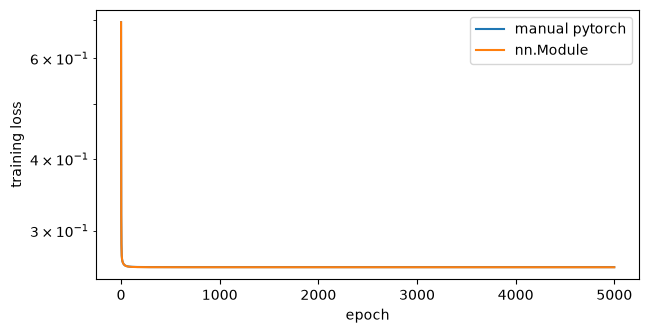

In [17]:
# training loss of the two PyTorch versions: flat at the end means they have (almost) converged
ax = pd.DataFrame({"manual pytorch": final_manual_history, "nn.Module": final_module_history}).plot(
    figsize=(7, 3.5), logy=True, xlabel="epoch", ylabel="training loss")

The numeric weights match sklearn. The state weights are all about 0.06 higher in PyTorch, and the bias is about 0.06 lower. Every order has exactly one state column equal to 1, so adding the same amount to every state weight and taking it off the bias gives exactly the same predictions. Only the small penalty separates those solutions, so the loss is almost flat in that direction and gradient descent moves along it very slowly. sklearn's solver gets to the exact minimum. This is why the weights differ more than the probabilities do.

## 7. Threshold

The model gives a probability, so to act on it I need a threshold: flag the order if its probability is at or above it. The threshold should come from what the mistakes cost.

- a miss (late order not flagged): the customer gets a surprise delay and we could not do anything about it
- a false alarm (on-time order flagged): we spent a message or a check for nothing

I assume a miss costs 5 and a false alarm costs 1. That ratio is my assumption, not something in the data. For a model with correct probabilities, flagging is worth it when 5 × p > 1 × (1 − p), which is p > 1/6 ≈ 0.17.

I try thresholds from 0.01 to 0.60 on validation and keep the cheapest one for each model.

best threshold per model: {'sklearn': 0.2, 'manual pytorch': 0.2, 'nn.Module': 0.2}
validation cost at that threshold: {'sklearn': 713.0, 'manual pytorch': 714.0, 'nn.Module': 714.0}
validation cost of never late: 780.0


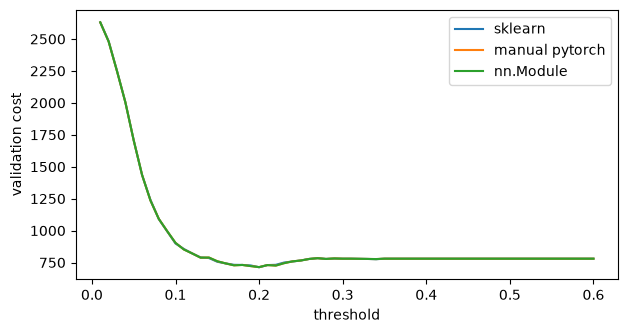

In [18]:
cost_fn = 5.0   # cost of a miss
cost_fp = 1.0   # cost of a false alarm


def total_cost(y_true, y_prob, threshold):
    y_pred = (np.asarray(y_prob) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return cost_fn * fn + cost_fp * fp


thresholds = np.arange(0.01, 0.61, 0.01)
val_cost_curves = pd.DataFrame(
    {name: [total_cost(y_val, p, t) for t in thresholds] for name, p in final_val_probs.items()},
    index=thresholds.round(2),
)
best_threshold = {name: float(val_cost_curves[name].idxmin()) for name in val_cost_curves}

print("best threshold per model:", best_threshold)
print("validation cost at that threshold:", val_cost_curves.min().to_dict())
print("validation cost of never late:", cost_fn * y_val.sum())
ax = val_cost_curves.plot(figsize=(7, 3.5), xlabel="threshold", ylabel="validation cost")

## 8. Test

Test is used once, here, with the thresholds from validation. Three baselines: constant (for log loss), never late and always late (for cost). A model is only useful if it costs less than both never late and always late.

In [19]:
final_test_probs = {
    "sklearn": final_sk.predict_proba(X_test_t)[:, 1],
    "manual pytorch": manual_prob(final_w, final_b, X_test_tensor),
    "nn.Module": module_prob(final_module, X_test_tensor),
}

constant, never, always = np.full(len(y_test), base_rate), np.zeros(len(y_test)), np.ones(len(y_test))
test_results = {
    "constant (train late rate)": {**evaluate(y_test, constant), "cost": total_cost(y_test, constant, 0.5)},
    "never late": {**evaluate(y_test, never), "cost": total_cost(y_test, never, 0.5)},
    "always late": {**evaluate(y_test, always), "cost": total_cost(y_test, always, 0.5)},
}
for name, p in final_test_probs.items():
    t = best_threshold[name]
    test_results[name] = {**evaluate(y_test, p, threshold=t), "cost": total_cost(y_test, p, t)}

test_table = pd.DataFrame(test_results).T
test_table[["log loss", "roc auc", "pr auc", "precision", "recall", "tp", "fp", "fn", "tn", "cost"]].round(3)

,log loss,roc auc,pr auc,precision,recall,tp,fp,fn,tn,cost
constant (train late rate),0.172,0.500,0.036,0.000,0.000,0.0,0.0,140.0,3729.0,700.0
never late,0.583,0.500,0.036,0.000,0.000,0.0,0.0,140.0,3729.0,700.0
always late,15.535,0.500,0.036,0.036,1.000,140.0,3729.0,0.0,0.0,3729.0
sklearn,0.183,0.636,0.066,0.062,0.179,25.0,380.0,115.0,3349.0,955.0
manual pytorch,0.183,0.636,0.066,0.062,0.179,25.0,381.0,115.0,3348.0,956.0
nn.Module,0.183,0.636,0.066,0.062,0.179,25.0,381.0,115.0,3348.0,956.0


On test the three models cost more than flagging nothing, and their log loss is worse than the constant baseline. They still rank orders better than chance (ROC AUC above 0.5), so the problem is the size of the probabilities. The next cell compares the average predicted probability with the real late rate in each split.

In [20]:
all_probs = {"train": final_sk.predict_proba(X_train_t)[:, 1], "val": final_val_probs["sklearn"],
             "test": final_test_probs["sklearn"]}
pd.DataFrame({
    name: {"actual late rate": d["late"].mean(), "mean predicted (sklearn)": all_probs[name].mean(),
           "mean promised_days": d["promised_days"].mean()}
    for name, d in [("train", train), ("val", val), ("test", test)]
}).T.round(3)

,actual late rate,mean predicted (sklearn),mean promised_days
train,0.080,0.080,24.532
val,0.055,0.078,23.423
test,0.036,0.099,20.705


On test the model predicts almost three times as many late orders as there are. Promised delivery times got shorter in the test months, but orders were not late more often. The model learned in train that a short promise means more risk, so on test it predicts too high.

## 9. Save

| file | what it holds |
|---|---|
| `preprocessor.joblib` | the fitted imputer, scaler and one-hot encoder |
| `sklearn_model.joblib` | the sklearn model |
| `manual_pytorch.pt` | the weights and bias of the manual model |
| `module_pytorch.pt` | the `state_dict` of the `nn.Module` model |
| `predictions.csv` | every order with its split, features, true label and the three probabilities |
| `metadata.json` | column lists, chosen settings, thresholds, costs and results |

In [21]:
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

joblib.dump(preprocessor, ARTIFACTS / "preprocessor.joblib")
joblib.dump(final_sk, ARTIFACTS / "sklearn_model.joblib")
torch.save({"w": final_w, "b": final_b}, ARTIFACTS / "manual_pytorch.pt")
torch.save(final_module.state_dict(), ARTIFACTS / "module_pytorch.pt")

pred_parts = []
for split_name, part, X_part_t, X_part_tensor in [("train", train, X_train_t, X_train_tensor),
                                                  ("val", val, X_val_t, X_val_tensor),
                                                  ("test", test, X_test_t, X_test_tensor)]:
    out = part.copy()
    out.insert(0, "split", split_name)
    out["prob_sklearn"] = final_sk.predict_proba(X_part_t)[:, 1]
    out["prob_manual"] = manual_prob(final_w, final_b, X_part_tensor)
    out["prob_module"] = module_prob(final_module, X_part_tensor)
    pred_parts.append(out)
pd.concat(pred_parts, ignore_index=True).to_csv(ARTIFACTS / "predictions.csv", index=False)


def to_json_safe(obj):
    # json can't store numpy numbers
    if isinstance(obj, dict):
        return {str(k): to_json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_json_safe(v) for v in obj]
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    return obj


metadata = {
    "feature_cols": feature_cols,
    "numeric_cols": numeric_cols,
    "categorical_cols": categorical_cols,
    "feature_names_after_preprocessing": list(feature_names),
    "n_features": n_features,
    "best_C": best_C,
    "best_lam": best_lam,
    "best_lr": best_lr,
    "n_epochs": n_epochs,
    "cost_fn": cost_fn,
    "cost_fp": cost_fp,
    "threshold_by_model": best_threshold,
    "train_late_rate": base_rate,
    "val_start": str(val_start.date()),
    "test_start": str(test_start.date()),
    "val_results": tuned_val.to_dict(orient="index"),
    "test_results": test_table.to_dict(orient="index"),
}
with open(ARTIFACTS / "metadata.json", "w") as f:
    json.dump(to_json_safe(metadata), f, indent=2)

print(sorted(p.name for p in ARTIFACTS.iterdir()))

['manual_pytorch.pt', 'metadata.json', 'module_pytorch.pt', 'predictions.csv', 'preprocessor.joblib', 'sklearn_model.joblib']


Last check: load everything back from disk, the way the app does, and make sure it gives the same test probabilities.

In [22]:
loaded_pre = joblib.load(ARTIFACTS / "preprocessor.joblib")
loaded_sk = joblib.load(ARTIFACTS / "sklearn_model.joblib")
loaded_manual = torch.load(ARTIFACTS / "manual_pytorch.pt")
loaded_module = LogisticModel(n_features)
loaded_module.load_state_dict(torch.load(ARTIFACTS / "module_pytorch.pt"))

X_check = loaded_pre.transform(X_test)
X_check_tensor = torch.tensor(X_check, dtype=torch.float32)

assert np.allclose(loaded_sk.predict_proba(X_check)[:, 1], final_test_probs["sklearn"])
assert np.allclose(manual_prob(loaded_manual["w"], loaded_manual["b"], X_check_tensor),
                   final_test_probs["manual pytorch"], atol=1e-6)
assert np.allclose(module_prob(loaded_module, X_check_tensor), final_test_probs["nn.Module"], atol=1e-6)
print("saved artifacts reproduce the test predictions")

saved artifacts reproduce the test predictions
